# Prototype A: crash-aware equity momentum factor

Hanyu Zhang | FINCB9339 Homework 2. This executed notebook explains the tested modules. It is an aggregate factor exposure experiment using a stylized funded capital convention, not a stock portfolio. Primary cash-plus-Mom returns are gross. Published findings are motivation, not values reproduced here.

## Inputs and units
French Mom is the average of small/big high prior-return portfolios minus the average of small/big low portfolios; daily portfolios are formed daily. Entries become decimal returns once. Official monthly Mom is a separate monthly construction. Cboe VIX is in points and is joined backward. Current snapshots can revise history; no point-in-time vintage is claimed.

In [1]:
from pathlib import Path
import sys, json, yaml, numpy as np, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from momentum_hw2.data_validation import load
from momentum_hw2.metrics import monthly, summary
cfg = yaml.safe_load((ROOT / 'config/base.yaml').read_text())
a, prices, rf, raw = load(cfg)
pd.options.display.float_format = '{:.5f}'.format
display(json.loads((ROOT / 'docs/research/freeze.json').read_text()))
display(a[['Mom','Mkt-RF','RF','VIX','vix_date','vix_staleness_days']].tail())

{'frozen_at_utc': '2026-10-04T14:28:00.331525+00:00',
 'stage': 'before data acquisition and strategy performance',
 'sha256': {'config/base.yaml': '2a69b965e7aabca964fc8f88ec389def5a26a55d085f7736bddf8737f93bb64f',
  'research/research_plan.md': '0d6381e1804976483fb18e3246c295346bd8cff4aa46f3fac2f2d84765169d65'}}

,Mom,Mkt-RF,RF,VIX,vix_date,vix_staleness_days
date,,,,,,
2026-08-25,-0.00060,0.00310,0.00010,15.45000,2026-08-25,0.00000
2026-08-26,0.00210,-0.00060,0.00010,15.21000,2026-08-26,0.00000
2026-08-27,-0.00230,0.00720,0.00010,14.51000,2026-08-27,0.00000
2026-08-28,-0.01470,-0.00340,0.00010,14.43000,2026-08-28,0.00000
2026-08-31,-0.00140,-0.00330,0.00010,14.92000,2026-08-31,0.00000


## Frozen decisions and timing
At the penultimate session close, annual volatility is $\sqrt{252}$ times sample standard deviation of 126 daily Mom observations. Vol scale is $\min(1.5,.10/\max(\sigma,.05))$. Bear uses negative compounded market **total** return over 24 comparable monthly snapshots. VIX >25 is the second flag. State scale is 1/.5/0 for zero/one/two flags. Execute final close; the prior exposure earns that day, and new exposure earns next session. This fixed heuristic is not Daniel–Moskowitz conditional-mean/variance sizing.

In [2]:
from momentum_hw2.backtest_factor import run_factor
results, decisions = run_factor(a, cfg['factor'])
display(decisions.head(3))
display(decisions.loc['2009-02-01':'2009-05-31'])

,month,signal_date,decision_date,first_return_date,bear_start,market_lookback,VIX,bear,high_vix,regime_scale,vol_scale,sigma,A0,A1,A2,A3
execution_date,,,,,,,,,,,,,,,,
1990-01-31,1990-01,1990-01-30,1990-01-30,1990-02-01,1988-01-28,0.34233,27.25000,0,1,0.50000,1.50000,0.06181,1.00000,1.50000,0.50000,0.75000
1990-02-28,1990-02,1990-02-27,1990-02-27,1990-03-01,1988-02-26,0.31965,22.69000,0,0,1.00000,1.50000,0.06136,1.00000,1.50000,1.00000,1.50000
1990-03-30,1990-03,1990-03-29,1990-03-29,1990-04-02,1988-03-30,0.36757,18.46000,0,0,1.00000,1.50000,0.05817,1.00000,1.50000,1.00000,1.50000


,month,signal_date,decision_date,first_return_date,bear_start,market_lookback,VIX,bear,high_vix,regime_scale,vol_scale,sigma,A0,A1,A2,A3
execution_date,,,,,,,,,,,,,,,,
2009-02-27,2009-02,2009-02-26,2009-02-26,2009-03-02,2007-02-27,-0.43171,44.66000,1,1,0.00000,0.27442,0.36440,1.00000,0.27442,0.00000,0.00000
2009-03-31,2009-03,2009-03-30,2009-03-30,2009-04-01,2007-03-29,-0.41091,45.54000,1,1,0.00000,0.24398,0.40987,1.00000,0.24398,0.00000,0.00000
2009-04-30,2009-04,2009-04-29,2009-04-29,2009-05-01,2007-04-27,-0.37230,36.08000,1,1,0.00000,0.22376,0.44691,1.00000,0.22376,0.00000,0.00000
2009-05-29,2009-05,2009-05-28,2009-05-28,2009-06-01,2007-05-30,-0.36522,31.67000,1,1,0.00000,0.22667,0.44117,1.00000,0.22667,0.00000,0.00000


## Reproduce an actual sizing calculation
Read the endpoints and intermediate volatility. The market index compounds Mkt-RF + RF, not market excess alone.

In [3]:
row = decisions.iloc[0]
s = row.signal_date
sigma = a.Mom.loc[:s].tail(126).std(ddof=1) * np.sqrt(252)
market_index = (1 + a['Mkt-RF'] + a.RF).cumprod()
bear_return = market_index.loc[s] / market_index.loc[row.bear_start] - 1
assert np.isclose(sigma, row.sigma)
assert np.isclose(bear_return, row.market_lookback)
display(pd.Series({'signal':s,'execution':decisions.index[0],'first_return':row.first_return_date,'sigma':sigma,'market_total_24m':bear_return,'vol_scale':row.vol_scale,'regime_scale':row.regime_scale,'combined':row.A3}))

signal              1990-01-30 00:00:00
execution           1990-01-31 00:00:00
first_return        1990-02-01 00:00:00
sigma                           0.06181
market_total_24m                0.34233
vol_scale                       1.50000
regime_scale                    0.50000
combined                        0.75000
dtype: object

## Capital accounting
$r_d=f_d+a_{previous}m_d-cost_d$. Mom is already an excess spread; do not subtract RF twice. Conventional unit notional is roughly long $1/short $1, gross 2; cap 1.5 permits gross 3. Earning RF on all collateral, borrow and financing access are assumptions. Zero factor exposure earns cash. At or below -100% modeled return, the pipeline stops rather than reporting a CAGR.

In [4]:
d = results['A3']['daily']
assert np.allclose((1+d.return_net).cumprod(), d.nav)
assert np.allclose(d.return_net, d.RF + d.excess_component)
for label,z in results.items():
    saved = pd.read_csv(ROOT/'results/tables'/f'{label}_daily.csv',index_col=0,parse_dates=True)
    assert np.allclose(z['daily'].return_net, saved.return_net, atol=1e-13)
display(pd.DataFrame({x:summary(z['daily']) for x,z in results.items()}).T[['CAGR','annual_vol','Sharpe','max_daily_drawdown','average_exposure']])

,CAGR,annual_vol,Sharpe,max_daily_drawdown,average_exposure
A0,0.07938,0.16174,0.39282,-0.63288,1.00000
A1,0.11762,0.12442,0.75071,-0.24129,0.98762
A2,0.10500,0.11476,0.70178,-0.26873,0.84122
A3,0.11994,0.10450,0.89354,-0.18893,0.88869


## Actual paths and component attribution
All variants use the same dates. Volatility management and states can reduce risk while lowering exposure. These historical outcomes do not guarantee future protection.

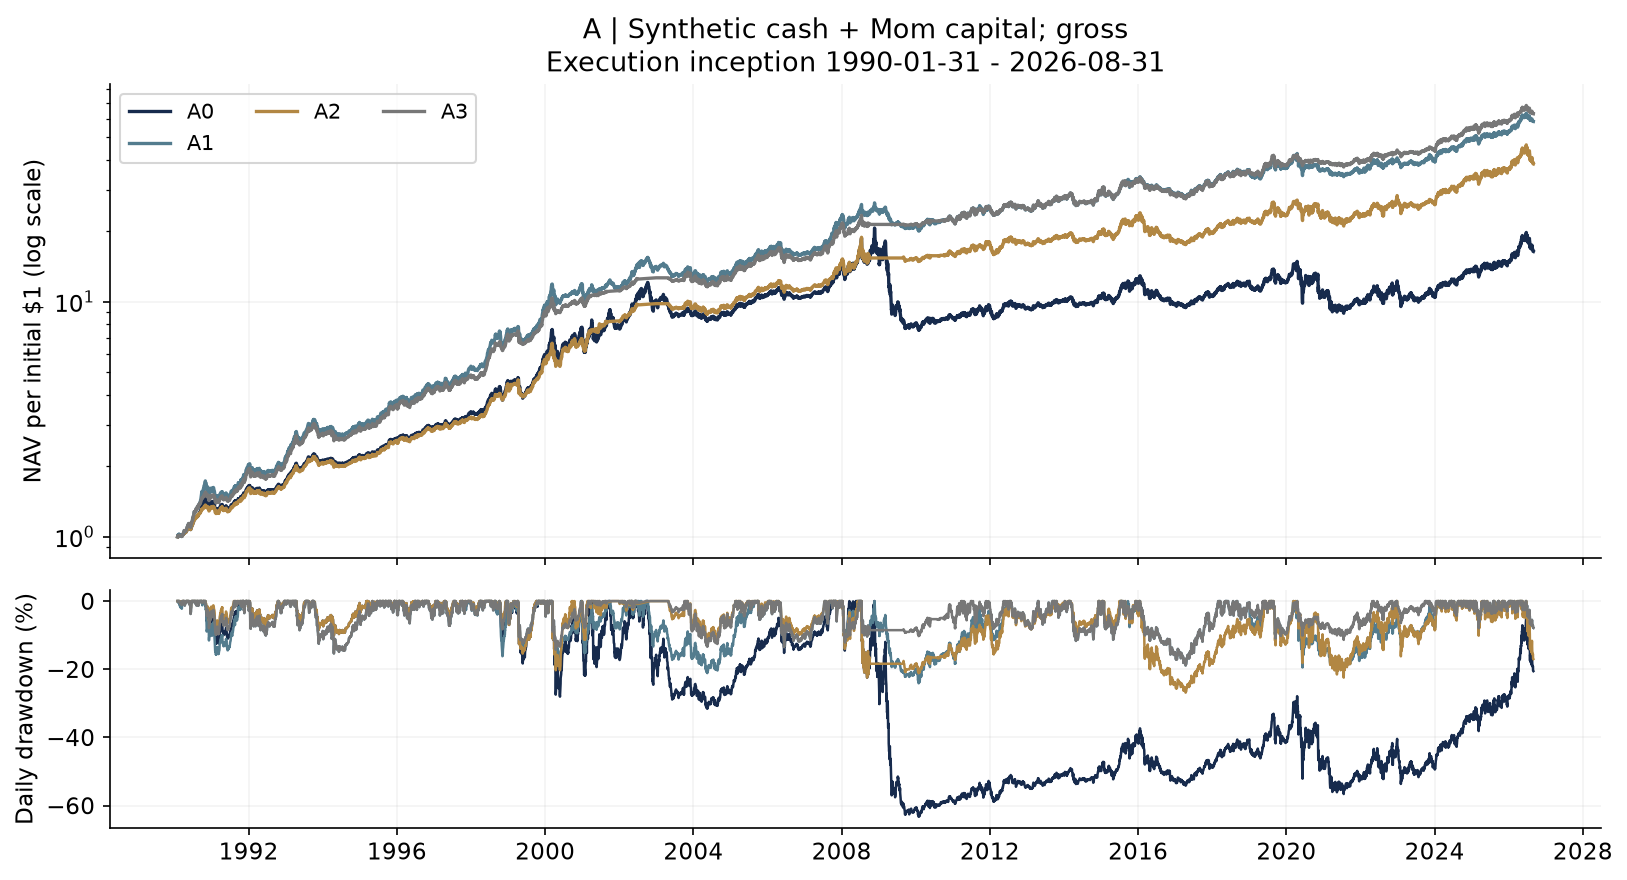

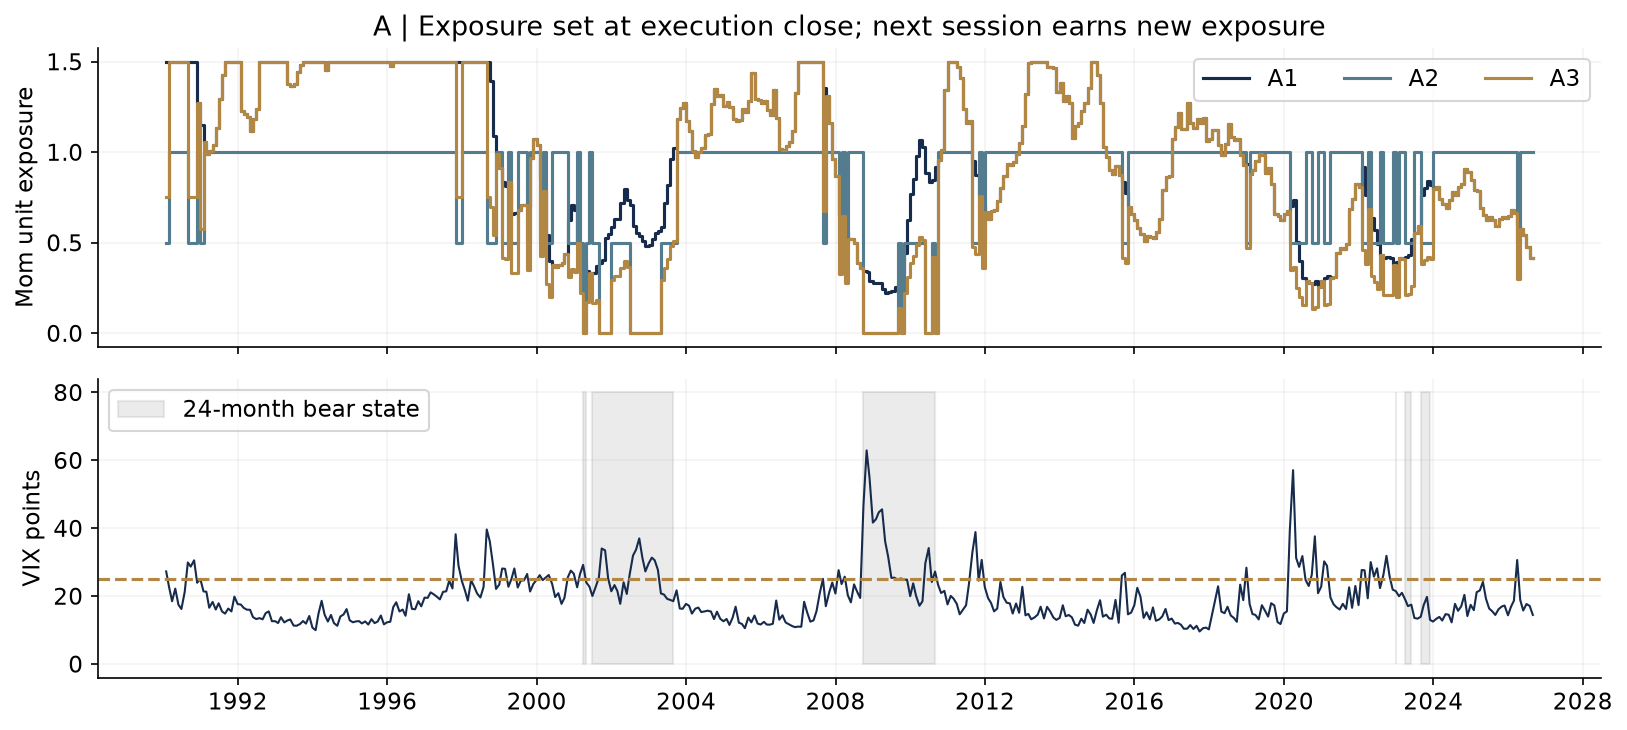

In [5]:
display(Image(filename=str(ROOT/'results/figures/A_nav_drawdown.png')))
display(Image(filename=str(ROOT/'results/figures/A_exposure_regime.png')))

## Sensitivity, crises and uncertainty
Defaults remain unchanged. Published WML decile crash numbers are not French Mom estimates. The 2009 rebound and 2020 remain in full-history performance. Long history without VIX is a distinct diagnostic.

In [6]:
display(pd.read_csv(ROOT/'results/tables/bootstrap.csv').query("prototype=='A'"))
display(pd.read_csv(ROOT/'results/tables/stress_periods.csv').query("variant.str.startswith('A') and period in ['2009_rebound','2020']",engine='python')[['variant','period','cumulative_return','max_daily_drawdown']])
display(pd.read_csv(ROOT/'results/tables/sensitivities.csv').query("prototype=='A'")[['variant','CAGR','Sharpe','max_daily_drawdown']])

,prototype,left,right,sample,n_months,block_months,replications,annual_excess_mean_difference,annual_excess_mean_difference_low,annual_excess_mean_difference_high,Sharpe_difference,Sharpe_difference_low,Sharpe_difference_high
0,A,A1,A0,full,439,6,1000,0.02939,0.00336,0.05669,0.35788,0.15105,0.54306
1,A,A1,A0,historical_holdout,80,6,1000,0.01480,-0.03617,0.07781,0.31980,0.06667,0.59285
2,A,A2,A0,full,439,6,1000,0.01674,-0.01262,0.05331,0.30896,0.08382,0.57259
3,A,A2,A0,historical_holdout,80,6,1000,0.02458,-0.01163,0.07557,0.28497,0.09579,0.52804
4,A,A3,A0,full,439,6,1000,0.02919,-0.00579,0.06698,0.50072,0.20832,0.76017
5,A,A3,A0,historical_holdout,80,6,1000,0.02044,-0.04486,0.10024,0.55144,0.19626,0.94588
6,A,A3,A1,full,439,6,1000,-0.00019,-0.01459,0.01336,0.14283,0.02588,0.25997
7,A,A3,A1,historical_holdout,80,6,1000,0.00565,-0.01121,0.02551,0.23164,0.02620,0.45132


,variant,period,cumulative_return,max_daily_drawdown
1,A0,2009_rebound,-0.45638,-0.51169
2,A0,2020,-0.10451,-0.33593
7,A1,2009_rebound,-0.13473,-0.15938
8,A1,2020,-0.01381,-0.19487
13,A2,2009_rebound,0.00000,0.00000
14,A2,2020,0.01128,-0.18182
19,A3,2009_rebound,0.00000,0.00000
20,A3,2020,0.03110,-0.10165


,variant,CAGR,Sharpe,max_daily_drawdown
0,primary,0.11994,0.89354,-0.18893
1,volatility_days_63,0.12136,0.91060,-0.20770
2,volatility_days_252,0.11608,0.84916,-0.18705
3,target_annual_volatility_0.08,0.10899,0.92611,-0.15357
4,target_annual_volatility_0.12,0.12756,0.86141,-0.22312
5,vix_threshold_points_20,0.10566,0.85724,-0.17473
6,vix_threshold_points_30,0.12486,0.85678,-0.18893
7,bear_lookback_months_12,0.12270,0.94823,-0.16374
8,bear_lookback_months_36,0.11748,0.87640,-0.18893
9,scale_cap_1.0,0.09976,0.82094,-0.18413


## Limits and sources
Aggregate returns cannot establish sector neutrality, new volatility-adjusted stock selection, constituent turnover, borrow availability or stock capacity. Exposure-change charges and implementation drags omit internal Mom trading. Daily/monthly series stay separate. Course lecture slides 65–88; Daniel & Moskowitz (2016), introduction and section 4; Kolanovic & Wei (2015), pp59–60. Exact local excerpts, provider/issuer URLs and dates are in docs/research/source_map.md. See README for offline commands.